# RealNVP Flow Tutorial: Learning to Transform Data Distributions

## What You'll Learn
- What are normalizing flows and why they're useful
- How RealNVP works to transform data distributions
- How to implement a RealNVP model from scratch
- How to train the model and visualize the results

## What is a Normalizing Flow?
A normalizing flow is a type of generative model that learns to transform a simple distribution (like a Gaussian) into a complex distribution (like our moon-shaped data). Think of it like learning to "mold" one shape into another!

## The RealNVP Approach
RealNVP uses "coupling layers" to gradually transform data. Each layer transforms half of the data while keeping the other half unchanged, making the transformation reversible and efficient.

Let's dive in! 🚀


In [7]:
# !pip install torch
# !pip install matplotlib pylab-sdk scikit-learn numpy pandas

In [1]:
# PyTorch for deep learning
import torch
from torch import nn, optim, distributions
from torch.nn import functional as F

# For data visualization
import matplotlib.pyplot as plt
from pylab import rcParams

# For generating our dataset
from sklearn import datasets
import numpy as np

# For file operations
import os

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.11.0+cu128
Using device: CUDA


## Step 2: Configuration and Setup

Let's set up our hyperparameters (settings that control how our model learns). These are like the "knobs" we can turn to adjust our model's behavior.


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 10            # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 2          # Our data has 2 dimensions (x, y coordinates)
OUTPUT_DIM = 2         # Output also has 2 dimensions
HIDDEN_DIM = 256       # Size of hidden layers in our neural networks
N_COUPLE_LAYERS = 8    # Number of coupling layers in our flow

# Visualization settings
SAVE_PLT_INTERVAL = 1  # How often to save plots

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("🔧 Configuration set up!")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Epochs: {EPOCHS}")
print(f"   Hidden dimension: {HIDDEN_DIM}")
print(f"   Number of coupling layers: {N_COUPLE_LAYERS}")
print(f"   Device: {device}")


🔧 Configuration set up!
   Batch size: 128
   Epochs: 10
   Hidden dimension: 256
   Number of coupling layers: 8
   Device: cuda


## Step 3: Create Our Dataset

We'll use the famous "two moons" dataset - it looks like two crescent moons! This is a great example because:
- It's simple to visualize (2D)
- It has a complex, non-linear shape
- It's perfect for testing normalizing flows

Let's generate and visualize our data:


🌙 Generating two moons dataset...
   Training data shape: (50000, 2)
   Test data shape: (1000, 2)


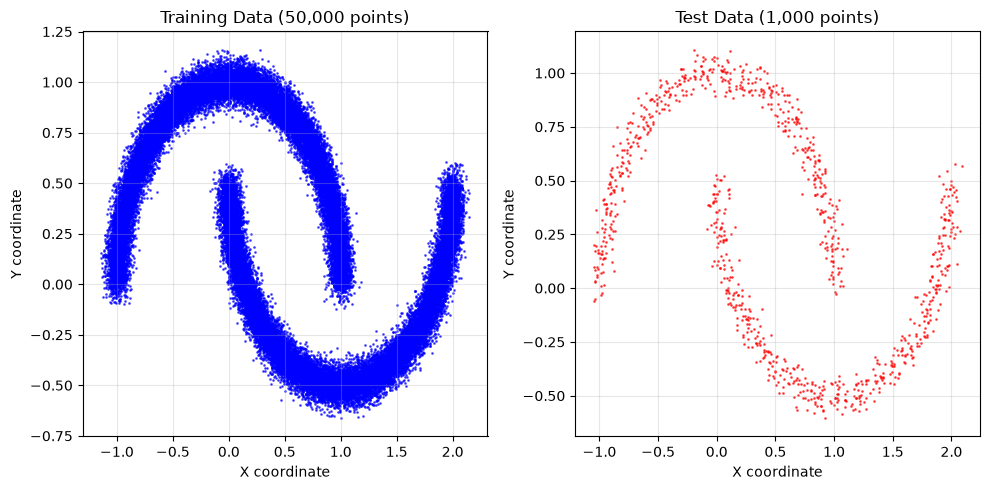

✅ Dataset created and visualized!
   Notice how the data forms two crescent moon shapes!


In [3]:
# Generate the two moons dataset
print("🌙 Generating two moons dataset...")

# Create training data (50,000 points)
train_data = datasets.make_moons(n_samples=50000, noise=0.05)[0].astype(np.float32)
print(f"   Training data shape: {train_data.shape}")

# Create test data (1,000 points)
test_data = datasets.make_moons(n_samples=1000, noise=0.05)[0].astype(np.float32)
print(f"   Test data shape: {test_data.shape}")

# Let's visualize our data
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Training Data (50,000 points)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(test_data[:, 0], test_data[:, 1], c='red', s=1, alpha=0.6)
plt.title('Test Data (1,000 points)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Dataset created and visualized!")
print("   Notice how the data forms two crescent moon shapes!")


## Step 4: Prepare Data Loaders

Data loaders help us feed data to our model in small batches during training. This is more memory-efficient than loading all data at once.


In [4]:
# Set up data loaders for efficient batch processing
print("📦 Setting up data loaders...")

# Convert numpy arrays to PyTorch tensors
train_tensor = torch.from_numpy(train_data)
test_tensor = torch.from_numpy(test_data)

# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 1, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_tensor, 
    batch_size=BATCH_SIZE, 
    shuffle=True,  # Randomize order for better training
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_tensor, 
    batch_size=BATCH_SIZE, 
    shuffle=True,
    **kwargs
)

print(f"✅ Data loaders created!")
print(f"   Training batches: {len(train_loader)}")
print(f"   Test batches: {len(test_loader)}")
print(f"   Batch size: {BATCH_SIZE}")

# Let's peek at one batch to see what it looks like
sample_batch = next(iter(train_loader))
print(f"   Sample batch shape: {sample_batch.shape}")
print(f"   Sample batch range: [{sample_batch.min():.3f}, {sample_batch.max():.3f}]")


📦 Setting up data loaders...
✅ Data loaders created!
   Training batches: 391
   Test batches: 8
   Batch size: 128
   Sample batch shape: torch.Size([128, 2])
   Sample batch range: [-1.043, 2.047]


## Step 5: Understanding the RealNVP Architecture

Now let's build our RealNVP model! The key idea is to use **coupling layers** that transform data step by step.

### What is a Coupling Layer?
A coupling layer is like a smart transformer that:
1. **Splits** the input data into two parts
2. **Transforms** one part based on the other part
3. **Combines** them back together

This makes the transformation reversible and efficient to compute!

Let's build it step by step:


## Structure of the Coupling Layer Jacobian

In a coupling layer, $x$ is split into two parts by mask $m$:

$$x = (x_m, x_{\bar{m}})$$

**Forward transform:**

$$y_m = x_m$$
$$y_{\bar{m}} = x_{\bar{m}} \odot e^{s(x_m)} + t(x_m)$$

So $y$ depends on $x$ as:

- The first block $y_m$ is just a copy → derivative w.r.t. $x_m$ is identity
- $y_{\bar{m}}$ depends linearly on $x_{\bar{m}}$ but not on $x_m$ except through $s, t$

Let's write the Jacobian matrix $J$ in block form:

$$J = \begin{pmatrix}
\frac{\partial y_m}{\partial x_m} & \frac{\partial y_m}{\partial x_{\bar{m}}} \\
\frac{\partial y_{\bar{m}}}{\partial x_m} & \frac{\partial y_{\bar{m}}}{\partial x_{\bar{m}}}
\end{pmatrix} = \begin{pmatrix}
I & 0 \\
\frac{\partial y_{\bar{m}}}{\partial x_m} & \text{diag}(e^s)
\end{pmatrix}$$

**Key observation:** upper-right block is zero (triangular matrix).

This means:

$$\det J = \det(I) \cdot \det(\text{diag}(e^s)) = 1 \cdot \prod_{i \in \bar{m}} e^{s_i} = e^{\sum_{i \in \bar{m}} s_i}$$

And so:

$$\log |\det J| = \sum_{i \in \bar{m}} s_i$$


## Forward and Inverse Passes

**Forward Pass:**
$x$ with the mask: 
- $x_m = m \odot x$ (kept)
- $x_{\bar{m}} = (1-m) \odot x$ (transformed)

You compute $s, t$ from the kept part:
$$s = s_\theta(x_m), \quad t = t_\theta(x_m)$$

Then set:
- $y_m = x_m$ (unchanged)
- $y_{\bar{m}} = x_{\bar{m}} \odot e^s + t$ (transformed)

In the inverse (backward) pass you’re given 
$y$. Crucially, 


$y_m = x_m$ (the masked coordinates are identical before/after). So the kept part you should condition on is now available as $y_m$. You recompute:
$$s = s_\theta(y_m), \quad t = t_\theta(y_m)$$

And invert:
$$x_{\bar{m}} = (y_{\bar{m}} - t) \odot e^{-s}$$

In [5]:
class CouplingLayer(nn.Module):
    """
    A coupling layer that transforms data using neural networks.
    
    The key idea: 
    - Split input x into two parts using a mask
    - Transform one part based on the other part
    - Combine them back together
    """
    
    def __init__(self, input_dim, output_dim, hid_dim, mask):
        super().__init__()
        
        # The mask determines which dimensions to transform
        # mask = [0, 1] means: don't transform dimension 0, transform dimension 1
        self.mask = mask
        
        # Neural networks to compute scaling (s) and translation (t) factors
        # These networks take the "untransformed" part and predict how to transform the other part
        
        # Scaling network (s): predicts how much to scale each dimension
        self.s_fc1 = nn.Linear(input_dim, hid_dim)
        self.s_fc2 = nn.Linear(hid_dim, hid_dim)
        self.s_fc3 = nn.Linear(hid_dim, output_dim)
        
        # Translation network (t): predicts how much to shift each dimension
        self.t_fc1 = nn.Linear(input_dim, hid_dim)
        self.t_fc2 = nn.Linear(hid_dim, hid_dim)
        self.t_fc3 = nn.Linear(hid_dim, output_dim)

    def forward(self, x):
        """
        Transform x to y using the coupling layer.
        Returns: y (transformed data) and log_det_jacobian (for computing likelihood)
        """
        # Apply mask to get the "untransformed" part
        x_m = x * self.mask
        
        # Compute scaling and translation factors from the untransformed part
        s_out = torch.tanh(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(x_m))))))
        t_out = self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(x_m)))))
        
        # Apply the transformation: y = x_m + (1-mask) * (x * exp(s) + t)
        # This means: keep the masked part unchanged, transform the unmasked part
        y = x_m + (1 - self.mask) * (x * torch.exp(s_out) + t_out)
        
        # Compute log determinant of Jacobian (needed for likelihood computation)
        log_det_jacobian = s_out.sum(dim=1)
        
        return y, log_det_jacobian

    def backward(self, y):
        """
        Reverse transformation: convert y back to x.
        This is what makes the flow invertible!
        """
        # Apply mask to get the "untransformed" part
        y_m = y * self.mask
        
        # Compute scaling and translation factors
        s_out = torch.tanh(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(y_m))))))
        
        t_out = self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(y_m)))))
        
        # Reverse the transformation: x = y_m + (1-mask) * (y - t) * exp(-s)
        x = y_m + (1 - self.mask) * (y - t_out) * torch.exp(-s_out)
        
        return x

print("✅ CouplingLayer class defined!")
print("   This is the building block of our RealNVP flow.")


✅ CouplingLayer class defined!
   This is the building block of our RealNVP flow.


Now let's build the complete RealNVP model by combining multiple coupling layers:


In [6]:
class RealNVP(nn.Module):
    """
    RealNVP (Real Non-Volume Preserving) flow model.
    
    This model chains multiple coupling layers together to create a powerful
    transformation from our complex data distribution to a simple Gaussian.
    """
    
    def __init__(self, input_dim, output_dim, hid_dim, mask, n_layers=6):
        super().__init__()
        
        # We need at least 2 layers to ensure all dimensions can be transformed
        assert n_layers >= 2, 'Number of coupling layers should be >= 2'
        
        # Create a list of coupling layers
        self.modules = []
        
        # First layer uses the given mask
        self.modules.append(CouplingLayer(input_dim, output_dim, hid_dim, mask))
        
        # Middle layers alternate the mask pattern
        # This ensures all dimensions get transformed
        for _ in range(n_layers - 2):
            mask = 1 - mask  # Flip the mask
            self.modules.append(CouplingLayer(input_dim, output_dim, hid_dim, mask))
        
        # Last layer uses the opposite mask
        self.modules.append(CouplingLayer(input_dim, output_dim, hid_dim, 1 - mask))
        
        # Convert to PyTorch ModuleList for proper parameter tracking
        self.module_list = nn.ModuleList(self.modules)
        
    def forward(self, x):
        """
        Transform data from complex distribution to simple Gaussian.
        Returns: z (transformed data) and sum of log determinants
        """
        ldj_sum = 0  # Sum of log determinant of Jacobian
        
        # Pass data through each coupling layer
        for module in self.module_list:
            x, ldj = module(x)
            ldj_sum += ldj
            
        return x, ldj_sum

    def backward(self, z):
        """
        Reverse transformation: convert from Gaussian back to complex distribution.
        This is how we generate new samples!
        """
        # Pass through layers in reverse order
        for module in reversed(self.module_list):
            z = module.backward(z)
            
        return z

print("✅ RealNVP class defined!")
print("   This combines multiple coupling layers into a complete flow model.")


✅ RealNVP class defined!
   This combines multiple coupling layers into a complete flow model.


Now let's create our model and set up the training components:


In [7]:
# Create the mask for our coupling layers
# mask = [0, 1] means: don't transform x-coordinate, transform y-coordinate
mask = torch.from_numpy(np.array([0, 1]).astype(np.float32))

# Create our RealNVP model
model = RealNVP(INPUT_DIM, OUTPUT_DIM, HIDDEN_DIM, mask, N_COUPLE_LAYERS)

# Set up the optimizer (Adam is a popular choice for neural networks)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Define our target distribution (simple 2D Gaussian)
# This is what we want our complex data to look like after transformation
prior_z = distributions.MultivariateNormal(torch.zeros(2), torch.eye(2))

print("🏗️ Model and training setup complete!")
print(f"   Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Mask pattern: {mask.numpy()}")
print(f"   Learning rate: 1e-4")
print(f"   Target distribution: 2D Gaussian (mean=0, std=1)")

# Let's see what our model looks like
print("\n📋 Model architecture:")
print(model)


🏗️ Model and training setup complete!
   Model parameters: 1,073,184
   Mask pattern: [0. 1.]
   Learning rate: 1e-4
   Target distribution: 2D Gaussian (mean=0, std=1)

📋 Model architecture:
RealNVP(
  (module_list): ModuleList(
    (0-7): 8 x CouplingLayer(
      (s_fc1): Linear(in_features=2, out_features=256, bias=True)
      (s_fc2): Linear(in_features=256, out_features=256, bias=True)
      (s_fc3): Linear(in_features=256, out_features=2, bias=True)
      (t_fc1): Linear(in_features=2, out_features=256, bias=True)
      (t_fc2): Linear(in_features=256, out_features=256, bias=True)
      (t_fc3): Linear(in_features=256, out_features=2, bias=True)
    )
  )
)


## Step 6: Training Functions

Now let's create the functions that will train our model. The key idea is to minimize the negative log-likelihood, which encourages our model to transform the complex data into a simple Gaussian distribution.


In [8]:
def train(epoch):
    """
    Train the model for one epoch.
    
    The training process:
    1. Transform our complex data to simple Gaussian space
    2. Compute the likelihood of the transformed data
    3. Minimize negative log-likelihood (maximize likelihood)
    """
    model.train()  # Set model to training mode
    train_loss = 0
    
    for batch_idx, data in enumerate(train_loader):
        # Clear gradients from previous iteration
        optimizer.zero_grad()
        
        # Transform data to Gaussian space
        z, log_det_j_sum = model(data)
        
        # Compute loss: negative log-likelihood
        # We want the transformed data to look like our target Gaussian
        loss = -(prior_z.log_prob(z) + log_det_j_sum).mean()
        
        # Backpropagate gradients
        loss.backward()
        
        # Update model parameters
        optimizer.step()
        
        # Track loss for monitoring
        cur_loss = loss.item()
        train_loss += cur_loss
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), cur_loss / len(data)))

    # Print average loss for this epoch
    avg_loss = train_loss / len(train_loader.dataset)
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, avg_loss))
    
    return avg_loss

print("✅ Training function defined!")
print("   This function will teach our model to transform the moon data into a Gaussian.")


✅ Training function defined!
   This function will teach our model to transform the moon data into a Gaussian.


Now let's create the test function that will evaluate our model and create visualizations:


In [9]:
def test(epoch):
    """
    Test the model and create visualizations.
    
    This function:
    1. Evaluates the model on test data
    2. Transforms test data to Gaussian space
    3. Creates visualizations to see how well the transformation works
    """
    model.eval()  # Set model to evaluation mode
    test_loss = 0
    
    # Arrays to store all test data for visualization
    x_all = np.array([[]]).reshape(0, 2)  # Original data
    z_all = np.array([[]]).reshape(0, 2)  # Transformed data
    
    with torch.no_grad():  # Don't compute gradients during testing
        for batch_idx, data in enumerate(test_loader):
            # Transform data to Gaussian space
            z, log_det_j_sum = model(data)
            
            # Compute test loss
            cur_loss = -(prior_z.log_prob(z) + log_det_j_sum).mean().item()
            test_loss += cur_loss
            
            # Store data for visualization
            x_all = np.concatenate((x_all, data.numpy()))
            z_all = np.concatenate((z_all, z.numpy()))
    
    # Create visualizations
    subfig_plot(1, x_all, -2, 3, -1, 1.5, 'Input: x ~ p(x)', 'b')
    subfig_plot(2, z_all, -3, 3, -3, 3, 'Output: z = f(x)', 'b')
    
    # Print test loss
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))
    
    return test_loss

print("✅ Test function defined!")
print("   This function will show us how well our model transforms the data.")


✅ Test function defined!
   This function will show us how well our model transforms the data.


Let's also create the sampling function that generates new data by reversing the transformation:


In [10]:
def sample(epoch):
    """
    Generate new samples by sampling from Gaussian and transforming back.
    
    This is the magic of normalizing flows - we can generate new data
    that follows the same distribution as our training data!
    """
    model.eval()
    
    with torch.no_grad():
        # Sample 1000 points from our target Gaussian distribution
        z = prior_z.sample((1000,))
        
        # Transform back to our complex distribution
        x = model.backward(z)
        
        # Convert to numpy for visualization
        z = z.numpy()
        x = x.numpy()
        
        # Create visualizations
        subfig_plot(3, z, -3, 3, -3, 3, 'Input: z ~ p(z)', 'r')
        subfig_plot(4, x, -2, 3, -1, 1.5, 'Output: x = g(z) (g: inverse of f)', 'r')
        
        # Save plots periodically
        if epoch % SAVE_PLT_INTERVAL == 0:
            if not os.path.exists('results'):
                os.makedirs('results')
            plt.savefig('results/' + 'result_' + str(epoch) + '.png')
            print(f"💾 Saved plot: results/result_{epoch}.png")

def subfig_plot(location, data, x_start, x_end, y_start, y_end, title, color):
    """
    Helper function to create subplots for visualization.
    """
    if location == 1:
        plt.clf()  # Clear the figure for the first subplot
    
    plt.subplot(2, 2, location)
    plt.scatter(data[:, 0], data[:, 1], c=color, s=1)
    plt.xlim(x_start, x_end)
    plt.ylim(y_start, y_end)
    plt.title(title)
    plt.pause(1e-2)  # Small pause for interactive plotting

print("✅ Sampling and visualization functions defined!")
print("   These will help us see how well our model learns to generate new data.")


✅ Sampling and visualization functions defined!
   These will help us see how well our model learns to generate new data.


## Step 7: Let's Train Our Model! 🚀

Now comes the exciting part - training our RealNVP model! We'll run through multiple epochs and watch as our model learns to transform the moon data into a Gaussian distribution.


🎯 Starting training...

📊 Epoch 1/10
------------------------------


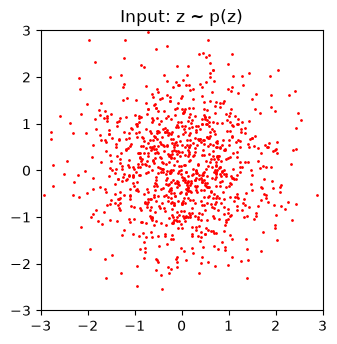

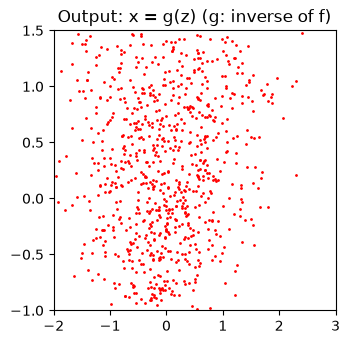

💾 Saved plot: results/result_1.png
Train Epoch: 1 [0/50000 (0%)]	Loss: 0.019741
Train Epoch: 1 [6400/50000 (13%)]	Loss: -0.035923
Train Epoch: 1 [12800/50000 (26%)]	Loss: -0.047914
Train Epoch: 1 [19200/50000 (38%)]	Loss: -0.050753
Train Epoch: 1 [25600/50000 (51%)]	Loss: -0.053010
Train Epoch: 1 [32000/50000 (64%)]	Loss: -0.053035
Train Epoch: 1 [38400/50000 (77%)]	Loss: -0.054988
Train Epoch: 1 [44800/50000 (90%)]	Loss: -0.054963
====> Epoch: 1 Average loss: -0.0469


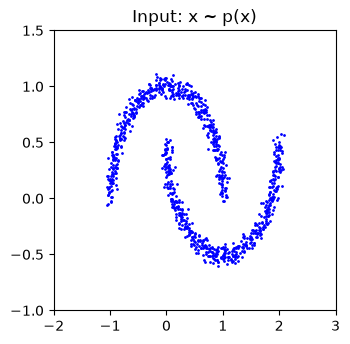

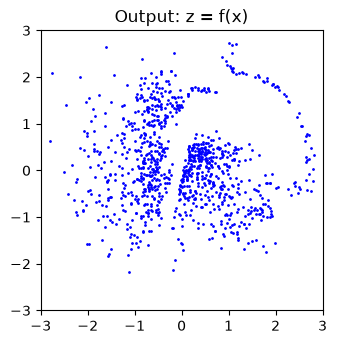

====> Test set loss: -0.0575
📈 Epoch 1 Summary:
   Train Loss: -0.0469
   Test Loss:  -0.0575

📊 Epoch 2/10
------------------------------


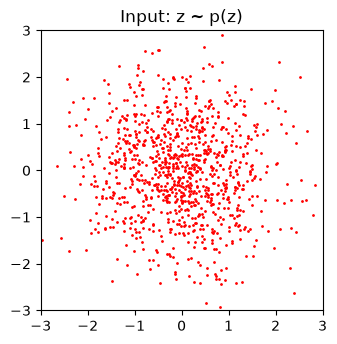

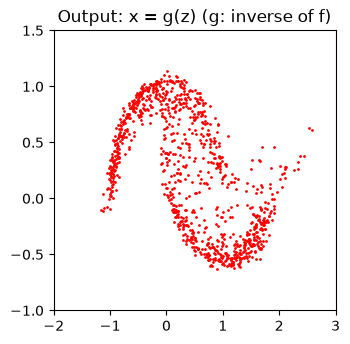

💾 Saved plot: results/result_2.png
Train Epoch: 2 [0/50000 (0%)]	Loss: -0.055165
Train Epoch: 2 [6400/50000 (13%)]	Loss: -0.055761
Train Epoch: 2 [12800/50000 (26%)]	Loss: -0.056346
Train Epoch: 2 [19200/50000 (38%)]	Loss: -0.055969
Train Epoch: 2 [25600/50000 (51%)]	Loss: -0.058205
Train Epoch: 2 [32000/50000 (64%)]	Loss: -0.058003
Train Epoch: 2 [38400/50000 (77%)]	Loss: -0.059016
Train Epoch: 2 [44800/50000 (90%)]	Loss: -0.058214
====> Epoch: 2 Average loss: -0.0575


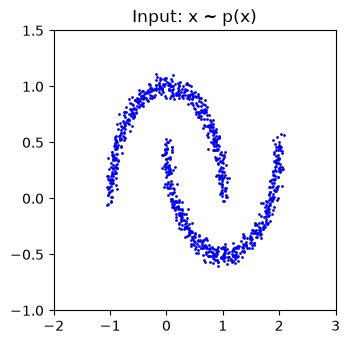

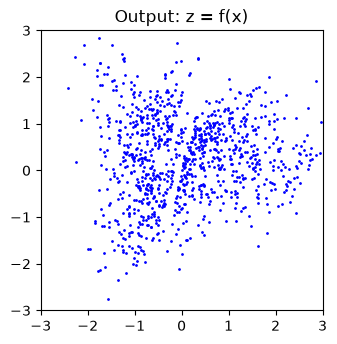

====> Test set loss: -0.0591
📈 Epoch 2 Summary:
   Train Loss: -0.0575
   Test Loss:  -0.0591

📊 Epoch 3/10
------------------------------


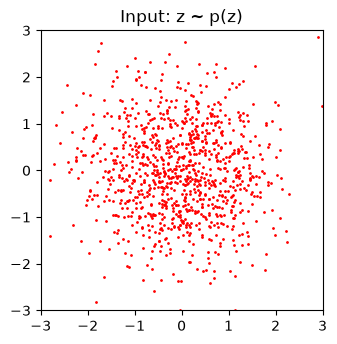

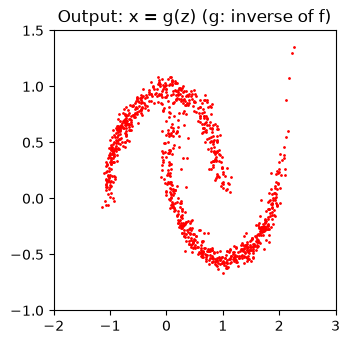

💾 Saved plot: results/result_3.png
Train Epoch: 3 [0/50000 (0%)]	Loss: -0.058469
Train Epoch: 3 [6400/50000 (13%)]	Loss: -0.059048
Train Epoch: 3 [12800/50000 (26%)]	Loss: -0.057835
Train Epoch: 3 [19200/50000 (38%)]	Loss: -0.058943
Train Epoch: 3 [25600/50000 (51%)]	Loss: -0.058611
Train Epoch: 3 [32000/50000 (64%)]	Loss: -0.058874
Train Epoch: 3 [38400/50000 (77%)]	Loss: -0.058891
Train Epoch: 3 [44800/50000 (90%)]	Loss: -0.058969
====> Epoch: 3 Average loss: -0.0586


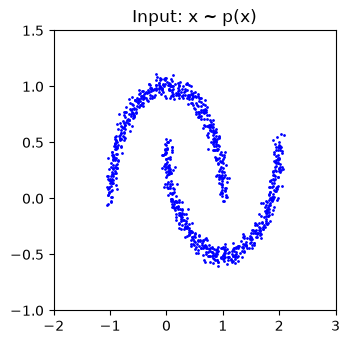

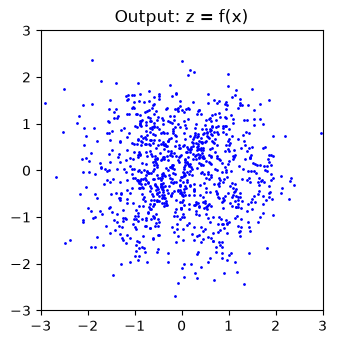

====> Test set loss: -0.0611
📈 Epoch 3 Summary:
   Train Loss: -0.0586
   Test Loss:  -0.0611

📊 Epoch 4/10
------------------------------


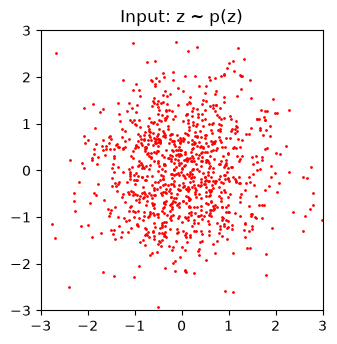

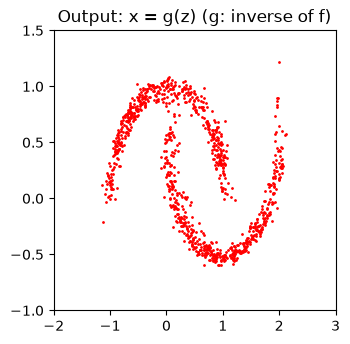

💾 Saved plot: results/result_4.png
Train Epoch: 4 [0/50000 (0%)]	Loss: -0.059162
Train Epoch: 4 [6400/50000 (13%)]	Loss: -0.058522
Train Epoch: 4 [12800/50000 (26%)]	Loss: -0.059417
Train Epoch: 4 [19200/50000 (38%)]	Loss: -0.058390
Train Epoch: 4 [25600/50000 (51%)]	Loss: -0.058982
Train Epoch: 4 [32000/50000 (64%)]	Loss: -0.059352
Train Epoch: 4 [38400/50000 (77%)]	Loss: -0.059159
Train Epoch: 4 [44800/50000 (90%)]	Loss: -0.059790
====> Epoch: 4 Average loss: -0.0591


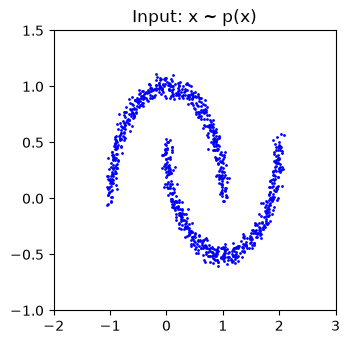

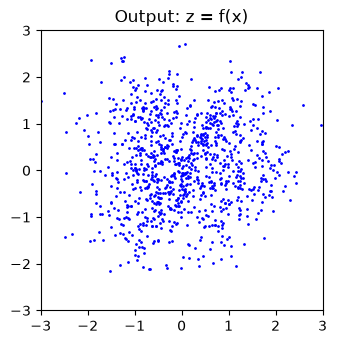

====> Test set loss: -0.0609
📈 Epoch 4 Summary:
   Train Loss: -0.0591
   Test Loss:  -0.0609

📊 Epoch 5/10
------------------------------


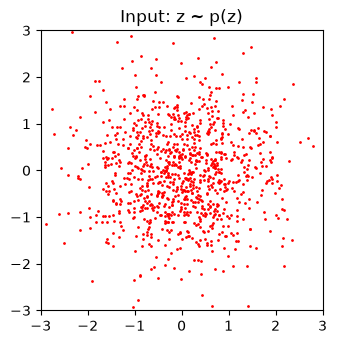

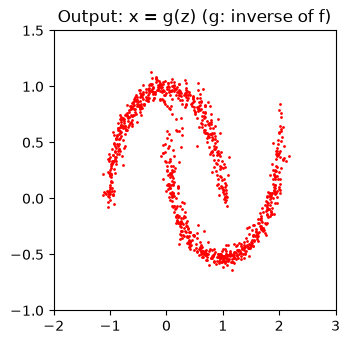

💾 Saved plot: results/result_5.png
Train Epoch: 5 [0/50000 (0%)]	Loss: -0.059723
Train Epoch: 5 [6400/50000 (13%)]	Loss: -0.059813
Train Epoch: 5 [12800/50000 (26%)]	Loss: -0.059115
Train Epoch: 5 [19200/50000 (38%)]	Loss: -0.059270
Train Epoch: 5 [25600/50000 (51%)]	Loss: -0.059789
Train Epoch: 5 [32000/50000 (64%)]	Loss: -0.059978
Train Epoch: 5 [38400/50000 (77%)]	Loss: -0.059390
Train Epoch: 5 [44800/50000 (90%)]	Loss: -0.059598
====> Epoch: 5 Average loss: -0.0592


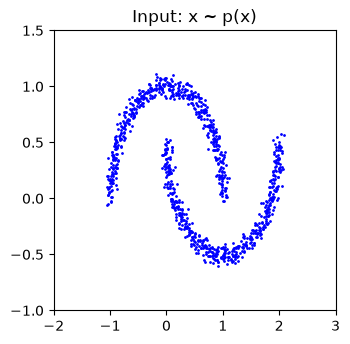

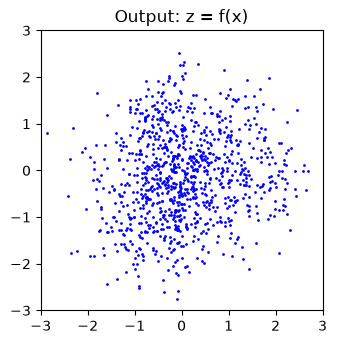

====> Test set loss: -0.0611
📈 Epoch 5 Summary:
   Train Loss: -0.0592
   Test Loss:  -0.0611

📊 Epoch 6/10
------------------------------


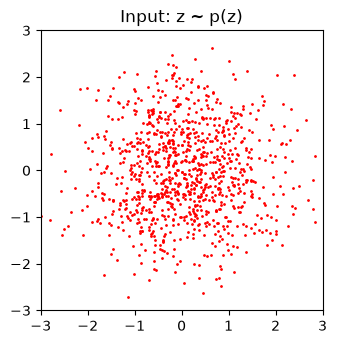

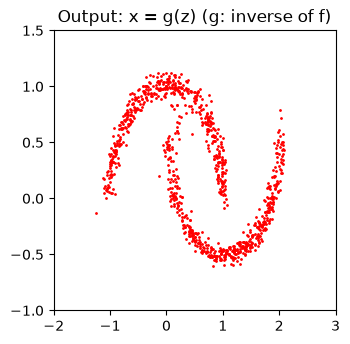

💾 Saved plot: results/result_6.png
Train Epoch: 6 [0/50000 (0%)]	Loss: -0.060474
Train Epoch: 6 [6400/50000 (13%)]	Loss: -0.059205
Train Epoch: 6 [12800/50000 (26%)]	Loss: -0.058503
Train Epoch: 6 [19200/50000 (38%)]	Loss: -0.058549
Train Epoch: 6 [25600/50000 (51%)]	Loss: -0.059615
Train Epoch: 6 [32000/50000 (64%)]	Loss: -0.058139
Train Epoch: 6 [38400/50000 (77%)]	Loss: -0.059036
Train Epoch: 6 [44800/50000 (90%)]	Loss: -0.060147
====> Epoch: 6 Average loss: -0.0594


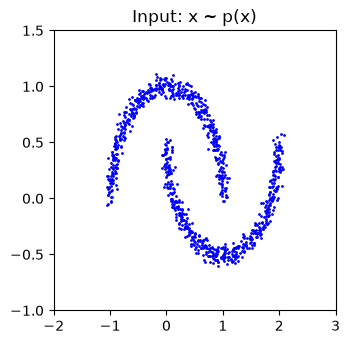

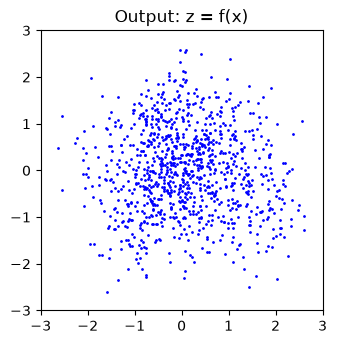

====> Test set loss: -0.0613
📈 Epoch 6 Summary:
   Train Loss: -0.0594
   Test Loss:  -0.0613

📊 Epoch 7/10
------------------------------


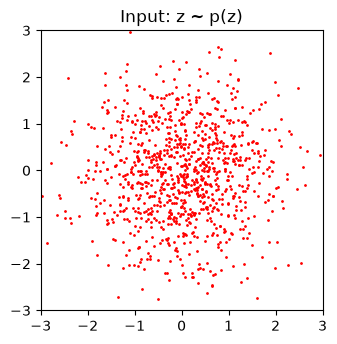

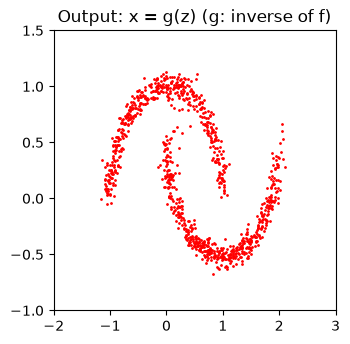

💾 Saved plot: results/result_7.png
Train Epoch: 7 [0/50000 (0%)]	Loss: -0.058130
Train Epoch: 7 [6400/50000 (13%)]	Loss: -0.058969
Train Epoch: 7 [12800/50000 (26%)]	Loss: -0.059643
Train Epoch: 7 [19200/50000 (38%)]	Loss: -0.059800
Train Epoch: 7 [25600/50000 (51%)]	Loss: -0.059627
Train Epoch: 7 [32000/50000 (64%)]	Loss: -0.059900
Train Epoch: 7 [38400/50000 (77%)]	Loss: -0.058747
Train Epoch: 7 [44800/50000 (90%)]	Loss: -0.059282
====> Epoch: 7 Average loss: -0.0595


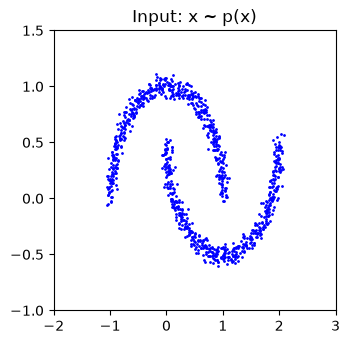

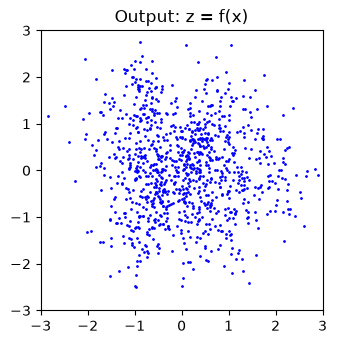

====> Test set loss: -0.0611
📈 Epoch 7 Summary:
   Train Loss: -0.0595
   Test Loss:  -0.0611

📊 Epoch 8/10
------------------------------


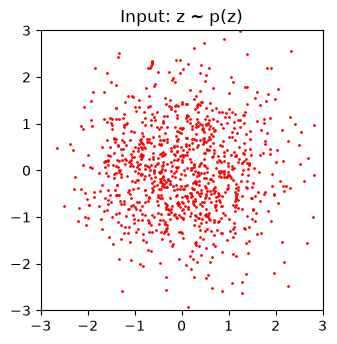

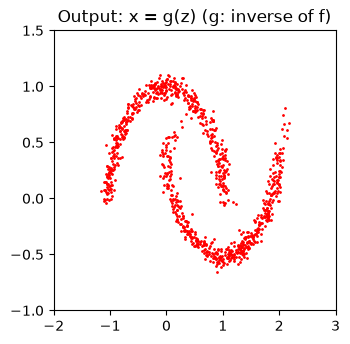

💾 Saved plot: results/result_8.png
Train Epoch: 8 [0/50000 (0%)]	Loss: -0.059879
Train Epoch: 8 [6400/50000 (13%)]	Loss: -0.059523
Train Epoch: 8 [12800/50000 (26%)]	Loss: -0.058650
Train Epoch: 8 [19200/50000 (38%)]	Loss: -0.059283
Train Epoch: 8 [25600/50000 (51%)]	Loss: -0.059558
Train Epoch: 8 [32000/50000 (64%)]	Loss: -0.059721
Train Epoch: 8 [38400/50000 (77%)]	Loss: -0.059297
Train Epoch: 8 [44800/50000 (90%)]	Loss: -0.059187
====> Epoch: 8 Average loss: -0.0595


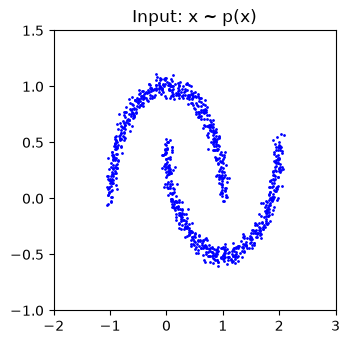

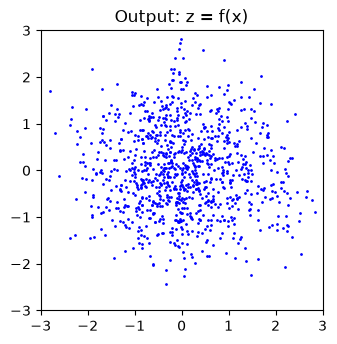

====> Test set loss: -0.0614
📈 Epoch 8 Summary:
   Train Loss: -0.0595
   Test Loss:  -0.0614

📊 Epoch 9/10
------------------------------


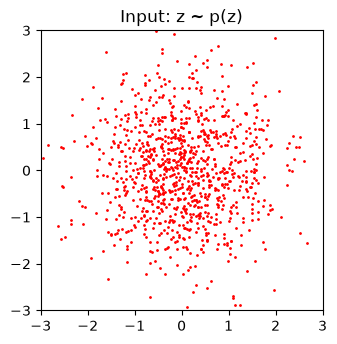

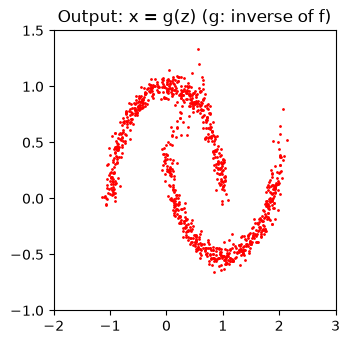

💾 Saved plot: results/result_9.png
Train Epoch: 9 [0/50000 (0%)]	Loss: -0.060157
Train Epoch: 9 [6400/50000 (13%)]	Loss: -0.060616
Train Epoch: 9 [12800/50000 (26%)]	Loss: -0.059941
Train Epoch: 9 [19200/50000 (38%)]	Loss: -0.059430
Train Epoch: 9 [25600/50000 (51%)]	Loss: -0.060366
Train Epoch: 9 [32000/50000 (64%)]	Loss: -0.059754
Train Epoch: 9 [38400/50000 (77%)]	Loss: -0.060218
Train Epoch: 9 [44800/50000 (90%)]	Loss: -0.058753
====> Epoch: 9 Average loss: -0.0596


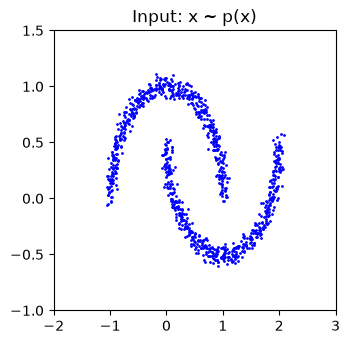

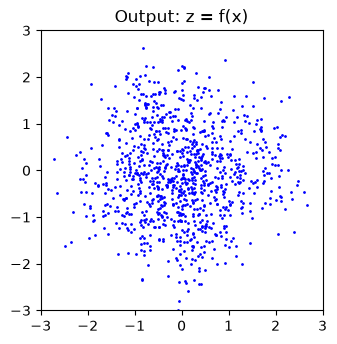

====> Test set loss: -0.0613
📈 Epoch 9 Summary:
   Train Loss: -0.0596
   Test Loss:  -0.0613

📊 Epoch 10/10
------------------------------


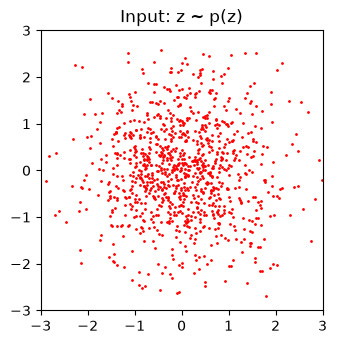

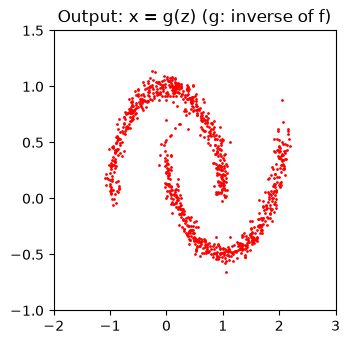

💾 Saved plot: results/result_10.png
Train Epoch: 10 [0/50000 (0%)]	Loss: -0.059672
Train Epoch: 10 [6400/50000 (13%)]	Loss: -0.058926
Train Epoch: 10 [12800/50000 (26%)]	Loss: -0.059799
Train Epoch: 10 [19200/50000 (38%)]	Loss: -0.059379
Train Epoch: 10 [25600/50000 (51%)]	Loss: -0.060316
Train Epoch: 10 [32000/50000 (64%)]	Loss: -0.059630
Train Epoch: 10 [38400/50000 (77%)]	Loss: -0.059409
Train Epoch: 10 [44800/50000 (90%)]	Loss: -0.059945
====> Epoch: 10 Average loss: -0.0596


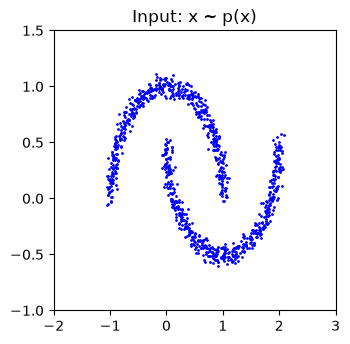

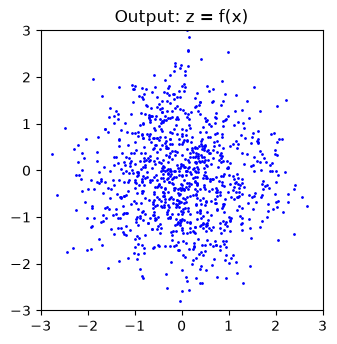

====> Test set loss: -0.0615
📈 Epoch 10 Summary:
   Train Loss: -0.0596
   Test Loss:  -0.0615

🎉 Training completed!
💾 Model saved as 'model.pth'


C:\Users\User\AppData\Local\Temp\ipykernel_828\3479536998.py:53: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.yscale('log')


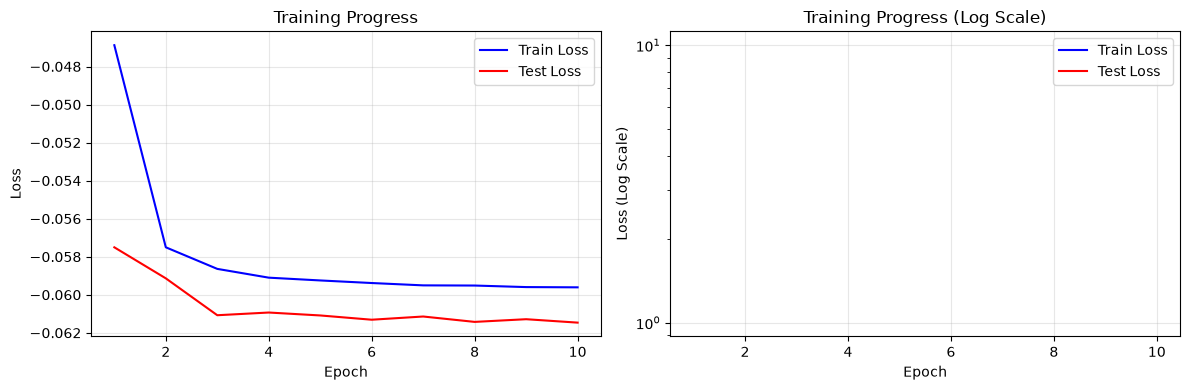

📊 Training progress plotted above!
   Lower loss = better model performance


In [11]:
# Training loop
print("🎯 Starting training...")
print("=" * 50)

# Lists to track training progress
train_losses = []
test_losses = []

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 30)
    
    # Generate samples to see current model performance
    sample(epoch)
    
    # Train the model
    train_loss = train(epoch)
    train_losses.append(train_loss)
    
    # Test the model
    test_loss = test(epoch)
    test_losses.append(test_loss)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train Loss: {train_loss:.4f}")
    print(f"   Test Loss:  {test_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 50)

# Save the trained model
torch.save(model.state_dict(), 'model.pth')
print("💾 Model saved as 'model.pth'")

# Plot training progress
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), train_losses, 'b-', label='Train Loss')
plt.plot(range(1, EPOCHS + 1), test_losses, 'r-', label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), train_losses, 'b-', label='Train Loss')
plt.plot(range(1, EPOCHS + 1), test_losses, 'r-', label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (Log Scale)')
plt.title('Training Progress (Log Scale)')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("📊 Training progress plotted above!")
print("   Lower loss = better model performance")


## Step 8: Let's Generate New Data! 🎨

Now for the fun part - let's use our trained model to generate new moon-shaped data! This demonstrates the power of normalizing flows for generative modeling.


🎨 Generating new moon-shaped data...


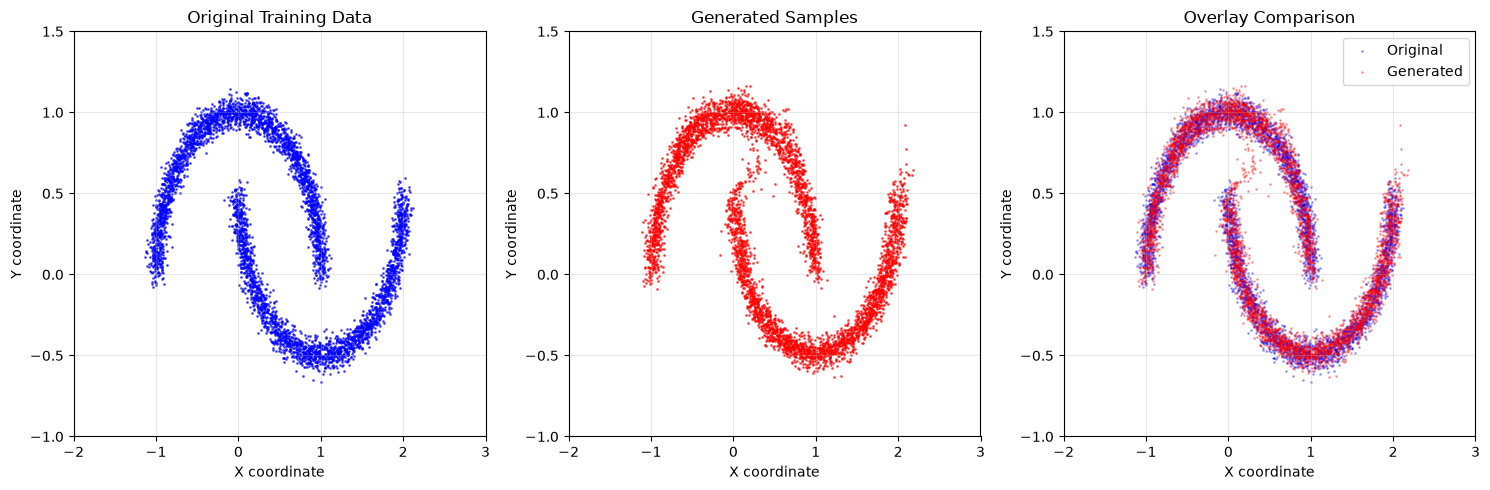

✅ New data generated!
   Compare the shapes - our model learned to generate moon-shaped data!
   The generated samples should look very similar to the original training data.


In [12]:
# Generate new samples using our trained model
print("🎨 Generating new moon-shaped data...")

model.eval()  # Set to evaluation mode

with torch.no_grad():
    # Sample from our target Gaussian distribution
    z_samples = prior_z.sample((5000,))  # Generate 5000 samples
    
    # Transform back to moon distribution
    x_generated = model.backward(z_samples)
    
    # Convert to numpy for visualization
    z_samples = z_samples.numpy()
    x_generated = x_generated.numpy()

# Create comparison visualization
plt.figure(figsize=(15, 5))

# Original training data
plt.subplot(1, 3, 1)
plt.scatter(train_data[:5000, 0], train_data[:5000, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(1, 3, 2)
plt.scatter(x_generated[:, 0], x_generated[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(1, 3, 3)
plt.scatter(train_data[:5000, 0], train_data[:5000, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_generated[:, 0], x_generated[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ New data generated!")
print("   Compare the shapes - our model learned to generate moon-shaped data!")
print("   The generated samples should look very similar to the original training data.")


Let's also visualize the transformation process step by step:


🔄 Visualizing the transformation process...


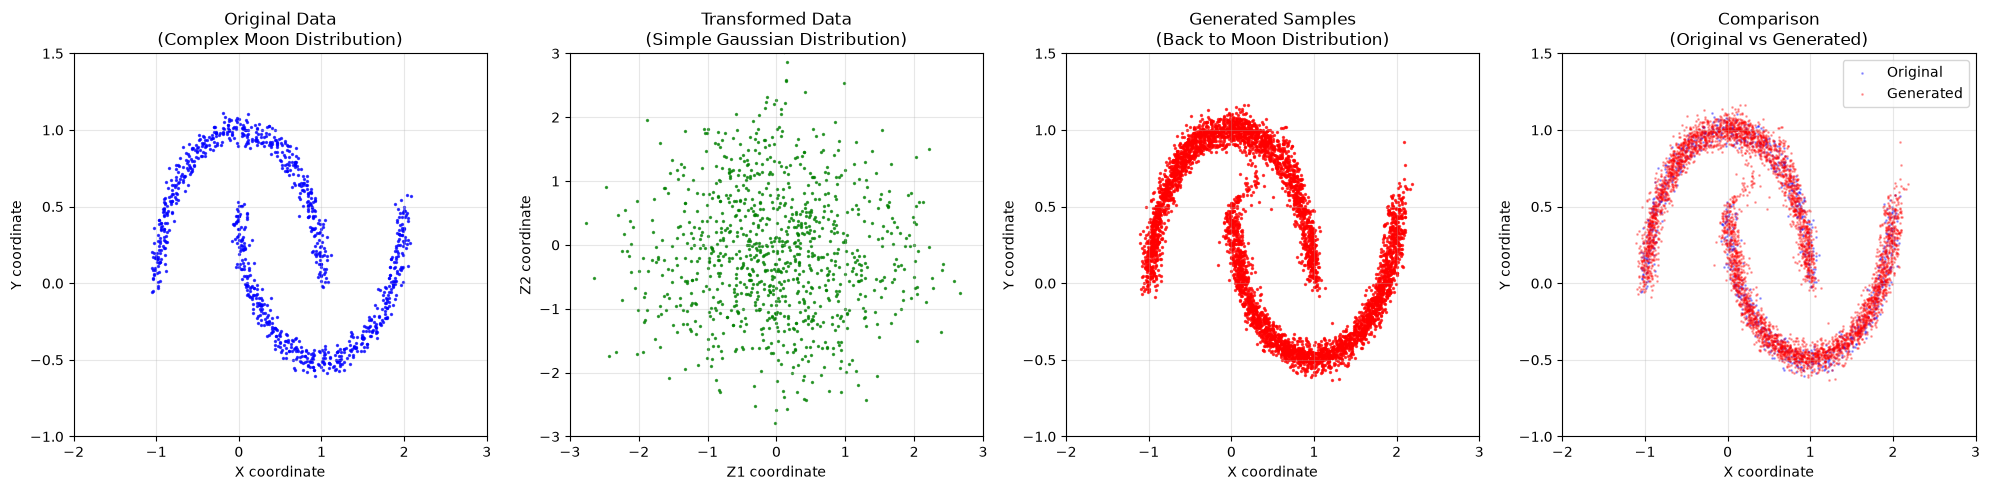

🎯 Transformation visualization complete!
   Notice how our model learned to:
   1. Transform complex moon data → simple Gaussian
   2. Transform simple Gaussian → complex moon data
   This is the power of normalizing flows!


In [13]:
# Let's see the transformation in action
print("🔄 Visualizing the transformation process...")

# Take a small sample of test data
sample_data = test_data[:1000]

model.eval()
with torch.no_grad():
    # Transform to Gaussian space
    z_transformed, _ = model(torch.from_numpy(sample_data))
    z_transformed = z_transformed.numpy()

# Create a comprehensive visualization
plt.figure(figsize=(20, 5))

# Original data
plt.subplot(1, 4, 1)
plt.scatter(sample_data[:, 0], sample_data[:, 1], c='blue', s=2, alpha=0.7)
plt.title('Original Data\n(Complex Moon Distribution)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.grid(True, alpha=0.3)

# Transformed data
plt.subplot(1, 4, 2)
plt.scatter(z_transformed[:, 0], z_transformed[:, 1], c='green', s=2, alpha=0.7)
plt.title('Transformed Data\n(Simple Gaussian Distribution)')
plt.xlabel('Z1 coordinate')
plt.ylabel('Z2 coordinate')
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.grid(True, alpha=0.3)

# Generated samples (reverse transformation)
plt.subplot(1, 4, 3)
plt.scatter(x_generated[:, 0], x_generated[:, 1], c='red', s=2, alpha=0.7)
plt.title('Generated Samples\n(Back to Moon Distribution)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.grid(True, alpha=0.3)

# All together
plt.subplot(1, 4, 4)
plt.scatter(sample_data[:, 0], sample_data[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_generated[:, 0], x_generated[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Comparison\n(Original vs Generated)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.xlim(-2, 3)
plt.ylim(-1, 1.5)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("🎯 Transformation visualization complete!")
print("   Notice how our model learned to:")
print("   1. Transform complex moon data → simple Gaussian")
print("   2. Transform simple Gaussian → complex moon data")
print("   This is the power of normalizing flows!")


## 🎉 Congratulations! You've Built a RealNVP Flow!

You've successfully and trained a RealNVP (Real Non-Volume Preserving) normalizing flow! Let's summarize what we accomplished:

### What We Learned:
1. **Normalizing Flows**: Models that learn to transform complex distributions into simple ones
2. **Coupling Layers**: The building blocks that make transformations reversible
3. **RealNVP Architecture**: How to chain multiple coupling layers for powerful transformations
4. **Training Process**: How to minimize negative log-likelihood to learn the transformation
5. **Generation**: How to create new data by reversing the learned transformation

### Key Concepts:
- **Forward Pass**: Complex data → Simple Gaussian
- **Backward Pass**: Simple Gaussian → Complex data (generation)
- **Invertibility**: The transformation can be reversed exactly
- **Jacobian Determinant**: Tracks how the transformation changes volumes

### What Makes This Special:
- ✅ **Exact Likelihood**: We can compute exact probabilities
- ✅ **Exact Sampling**: We can generate exact samples
- ✅ **Bijective**: Every input maps to exactly one output
- ✅ **Efficient**: Fast training and sampling


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Increase `N_COUPLE_LAYERS` (try 12, 16)
   - Change `HIDDEN_DIM` (try 128, 512)
   - Modify learning rate (try 1e-3, 1e-5)
3. **Visualize Training**: Watch how the transformation evolves during training

### Intermediate Experiments:
4. **3D Data**: Extend to 3D datasets and visualize with 3D plots
5. **Different Masks**: Try different masking patterns
6. **More Complex Data**: Use real datasets like MNIST (flattened images)

### Advanced Experiments:
7. **Conditional Flows**: Learn different transformations for different classes
8. **Autoregressive Flows**: Implement more sophisticated flow architectures
9. **Higher Dimensions**: Apply to image data or other high-dimensional problems

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
N_COUPLE_LAYERS = 16  # More layers
HIDDEN_DIM = 512      # Larger networks

# Try different learning rates
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **RealNVP Paper**: "Density estimation using Real NVP" by Dinh et al. (2017)
2. **Normalizing Flows**: "Normalizing Flows for Probabilistic Modeling and Inference" by Papamakarios et al. (2021)
3. **Flow-based Models**: "Variational Inference with Normalizing Flows" by Rezende & Mohamed (2015)

### Libraries to Explore:
- **nflows**: A PyTorch library for normalizing flows
- **FrEIA**: Framework for Easily Invertible Architectures
- **Glow**: Generative Flow with Invertible 1x1 Convolutions

### Applications:
- **Image Generation**: Creating realistic images
- **Data Augmentation**: Generating more training data
- **Density Estimation**: Understanding data distributions
- **Anomaly Detection**: Finding unusual patterns in data
- **Molecular Design**: Generating new chemical compounds

### Key Takeaways:
- Normalizing flows are powerful tools for generative modeling
- They provide exact likelihoods and exact sampling
- RealNVP is a great starting point for understanding flows
- The key insight is learning invertible transformations
- Visualization is crucial for understanding what the model learns

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new!*
